# 05. Product Forecast and Business Recommendations

**Goal:** turn the analysis into things a shop owner can act on: how much of each product to prepare, and when to have staff and stock ready.

**Inputs:** the raw sales file, `daily_sales.csv` (notebook 01) and `forecast_next_30_days_all_models.csv` (notebook 04). Run those notebooks first.

**Reminder:** this is a historical dataset. The forecast window (24 Mar to 22 Apr 2025) lies in the past, so these are portfolio recommendations, not live orders. Currency is not stated in the file.

**Parts**
1. Is the product mix stable enough to split a total forecast by product?
2. Product-level forecast for the next 30 days, with a range
3. Test: how accurate are 30-day product totals?
4. Peak times: weekday x hour
5. Daily prep guide per product
6. Recommendations and limits

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
BROWN, RED, GREEN, GREY = "#6F4E37", "#C1272D", "#2A7F62", "#8A8A8A"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
for p in (FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.savefig(FIG / name, bbox_inches="tight")
    plt.show()

df = pd.read_csv(ROOT / "data" / "raw" / "Coffe_sales.csv", parse_dates=["Date"])
daily = pd.read_csv(ROOT / "data" / "processed" / "daily_sales.csv", parse_dates=["date"], index_col="date")
fut = pd.read_csv(TAB / "forecast_next_30_days_all_models.csv", parse_dates=["date"], index_col="date")

LAST = df["Date"].max()
RECENT_DAYS = 49                                  # 7 full weeks, starting Monday 3 Feb 2025: the period after the jump in volume
RECENT_START = LAST - pd.Timedelta(days=RECENT_DAYS - 1)
recent = df[df["Date"] >= RECENT_START]
print(f"Recent period: {RECENT_START.date()} to {LAST.date()} ({RECENT_DAYS} days, {recent['Date'].nunique()} with sales)")

Recent period: 2025-02-03 to 2025-03-23 (49 days, 49 with sales)


## 1. Is the product mix stable?

If each product keeps about the same share of revenue, a total forecast can be split by product. If shares swing a lot, the split is unreliable.

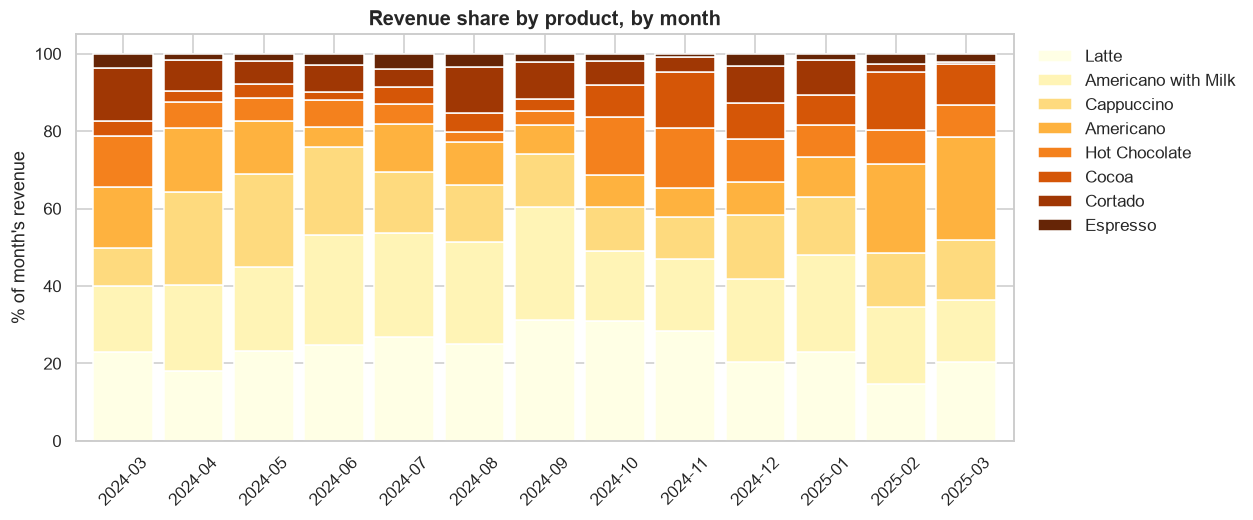

,average share,max - min share (percentage points)
coffee_name,,
Latte,23.8%,16.6
Americano with Milk,22.4%,13.3
Cappuccino,16.0%,14.3
Americano,12.8%,21.4
Hot Chocolate,8.6%,12.8
Cocoa,6.9%,13.2
Cortado,7.1%,13.2
Espresso,2.5%,3.2


In [3]:
df["month"] = df["Date"].dt.to_period("M")
mix = df.pivot_table(index="month", columns="coffee_name", values="money", aggfunc="sum")
mix_share = mix.div(mix.sum(axis=1), axis=0)
order = df.groupby("coffee_name")["money"].sum().sort_values(ascending=False).index
mix_share = mix_share[order]

ax = mix_share.mul(100).plot.bar(stacked=True, figsize=(11, 4.8), colormap="YlOrBr", width=.85, edgecolor="white")
ax.set(title="Revenue share by product, by month", xlabel="", ylabel="% of month's revenue")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False); ax.tick_params(axis="x", rotation=45)
save_fig("19_product_mix_by_month.png")

spread = (mix_share.max() - mix_share.min()).mul(100).round(1).rename("max - min share (percentage points)")
display(pd.DataFrame({"average share": mix_share.mean().map("{:.1%}".format), spread.name: spread}))

**Reading this:** if the gap between a product's highest and lowest monthly share is a few percentage points, the split is fairly stable. Larger gaps mean a product's share moves, so its forecast is less certain. In this dataset the gaps are large, so the product split below is only a rough guide.

## 2. Product forecast for the next 30 days

Total revenue forecasts come from notebook 04. Each product gets its share of revenue in the **last 7 weeks** (the period after the volume jump). To show uncertainty, the low and high ends come from the best simple, Holt-Winters, ARIMA and combination methods. `naive_last` is left out: it repeats a single Sunday and is not a serious forecast.

In [4]:
GOOD = [c for c in fut.columns if c != "naive_last"]
totals = fut[GOOD].sum()
central, low, high = totals["combo"], totals.min(), totals.max()
print(f"30-day total revenue forecast: central (combo) {central:,.0f}; range across methods {low:,.0f} to {high:,.0f}")

p = recent.groupby("coffee_name").agg(revenue=("money", "sum"), cups=("money", "size"))
p["share"] = p["revenue"] / p["revenue"].sum()
p["avg_price"] = p["revenue"] / p["cups"]
p = p.sort_values("share", ascending=False)

pf = pd.DataFrame({
    "share (last 7 weeks)": p["share"],
    "avg price": p["avg_price"],
    "revenue forecast (central)": p["share"] * central,
    "revenue low": p["share"] * low,
    "revenue high": p["share"] * high,
})
pf["cups forecast (central)"] = pf["revenue forecast (central)"] / pf["avg price"]
pf["cups low"] = pf["revenue low"] / pf["avg price"]
pf["cups high"] = pf["revenue high"] / pf["avg price"]
pf.loc["TOTAL"] = [pf["share (last 7 weeks)"].sum(), np.nan, *pf[["revenue forecast (central)", "revenue low", "revenue high"]].sum(),
                   *pf[["cups forecast (central)", "cups low", "cups high"]].sum()]
display(pf.round(2))
pf.round(2).to_csv(TAB / "product_forecast.csv")

30-day total revenue forecast: central (combo) 14,135; range across methods 13,145 to 14,478


,share (last 7 weeks),avg price,revenue forecast (central),revenue low,revenue high,cups forecast (central),cups low,cups high
coffee_name,,,,,,,,
Americano,0.25,25.96,3554.53,3305.64,3640.91,136.92,127.34,140.25
Americano with Milk,0.18,30.86,2527.55,2350.57,2588.98,81.90,76.17,83.89
Latte,0.17,35.76,2369.93,2203.99,2427.53,66.27,61.63,67.88
Cappuccino,0.14,35.76,2012.21,1871.31,2061.11,56.27,52.33,57.64
Cocoa,0.14,35.76,1922.78,1788.14,1969.50,53.77,50.00,55.08
Hot Chocolate,0.09,35.76,1229.68,1143.58,1259.57,34.39,31.98,35.22
Espresso,0.03,21.06,355.51,330.62,364.15,16.88,15.70,17.29
Cortado,0.01,25.96,162.31,150.94,166.25,6.25,5.81,6.40
TOTAL,1.00,NaN,14134.50,13144.80,14478.00,452.66,420.96,463.66


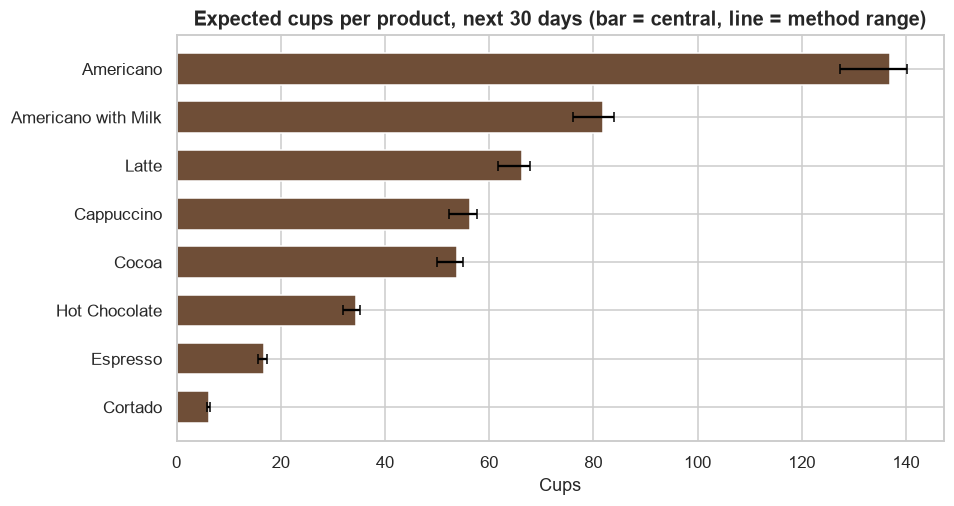

In [5]:
body = pf.drop("TOTAL")
fig, ax = plt.subplots(figsize=(9, 4.8))
y_pos = np.arange(len(body))
ax.barh(y_pos, body["cups forecast (central)"], color=BROWN, height=.65)
ax.errorbar(body["cups forecast (central)"], y_pos,
            xerr=[body["cups forecast (central)"] - body["cups low"], body["cups high"] - body["cups forecast (central)"]],
            fmt="none", ecolor="black", capsize=3)
ax.set_yticks(y_pos, body.index); ax.invert_yaxis()
ax.set(title="Expected cups per product, next 30 days (bar = central, line = method range)", xlabel="Cups")
save_fig("20_product_forecast.png")

## 3. How accurate are 30-day product totals?

A quick test on the same rolling origins as before: forecast each product's next-30-day revenue as *(last 28 days average) x 30*, and compare with what happened. The error is the product's total miss divided by its actual revenue.

In [6]:
dp = df.pivot_table(index="Date", columns="coffee_name", values="money", aggfunc="sum").reindex(daily.index).fillna(0)
dp_ok = dp.where(daily["reported"], np.nan)          # no-data days are not counted
H, START = 30, 120
origins = list(range(START, len(dp_ok) - H + 1, 7))

rows = []
for o in origins:
    hist, act = dp_ok.iloc[:o], dp_ok.iloc[o:o + H]
    fc = hist.iloc[-28:].mean() * H
    actual = act.sum()                                # sum() skips NaN: days without data add nothing
    # scale the forecast to the number of days that had data, so the comparison is fair
    fc = fc * act.notna().all(axis=1).sum() / H
    rows.append(pd.DataFrame({"origin": o, "product": fc.index, "forecast": fc.values, "actual": actual.values}))
pt = pd.concat(rows)
acc = pt.groupby("product").apply(lambda g: pd.Series({
    "WAPE of 30-day total": (g["forecast"] - g["actual"]).abs().sum() / g["actual"].sum(),
    "bias": (g["forecast"] - g["actual"]).sum() / g["actual"].sum()})).sort_values("WAPE of 30-day total")
tot = pt.groupby("origin")[["forecast", "actual"]].sum()
print(f"All products together: WAPE of the 30-day total = {(tot['forecast'] - tot['actual']).abs().sum() / tot['actual'].sum():.0%}")
acc.assign(**{"WAPE of 30-day total": acc["WAPE of 30-day total"].map("{:.0%}".format), "bias": acc["bias"].map("{:+.0%}".format)})

All products together: WAPE of the 30-day total = 25%


,WAPE of 30-day total,bias
product,,
Americano with Milk,24%,-3%
Cappuccino,26%,-4%
Latte,30%,-3%
Espresso,41%,-4%
Americano,41%,-28%
Hot Chocolate,47%,-9%
Cocoa,48%,-20%
Cortado,51%,+1%


**Reading this:** totals over 30 days are far steadier than single days, but the error is still sizeable because of the level changes in this dataset. Products with small revenue have larger relative errors. Treat the product forecast as a range, and re-run it often.

## 4. Peak times: weekday x hour

Average cups per hour on each weekday, using the last 7 weeks only (after the volume jump).

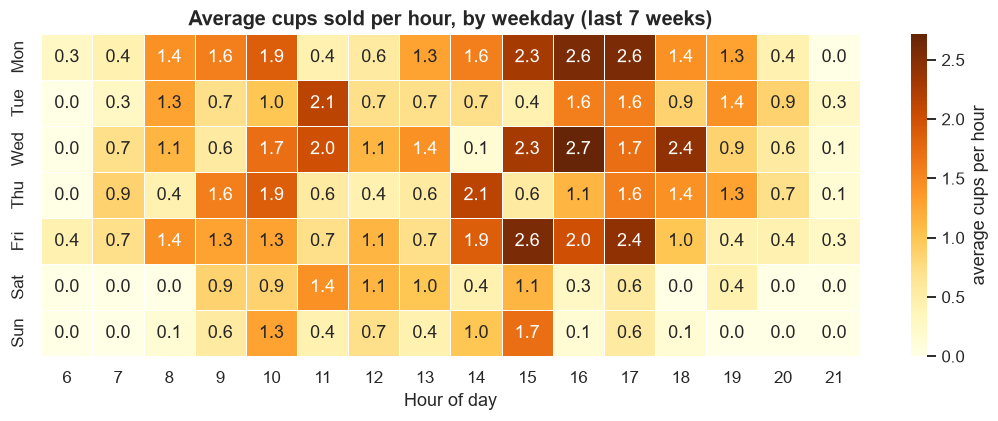

,weekday,hour,avg cups
0,Wed,16,2.7
1,Fri,15,2.6
2,Mon,16,2.6
3,Mon,17,2.6
4,Fri,17,2.4
5,Wed,18,2.4
6,Mon,15,2.3
7,Wed,15,2.3
8,Thu,14,2.1
9,Tue,11,2.1


In [7]:
n_days = recent.groupby("Weekday")["Date"].nunique()          # how many Mondays, Tuesdays... in the period
wk_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
cnt = recent.pivot_table(index="Weekday", columns="hour_of_day", values="money", aggfunc="size", fill_value=0).reindex(wk_order)
avg_cups = cnt.div(n_days.reindex(wk_order), axis=0)

fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(avg_cups, cmap="YlOrBr", annot=True, fmt=".1f", cbar_kws={"label": "average cups per hour"}, ax=ax, linewidths=.5)
ax.set(title="Average cups sold per hour, by weekday (last 7 weeks)", xlabel="Hour of day", ylabel="")
save_fig("21_weekday_hour_heatmap.png")

slots = avg_cups.stack().rename("avg cups").reset_index().sort_values("avg cups", ascending=False).head(10)
slots.columns = ["weekday", "hour", "avg cups"]
display(slots.round(1).reset_index(drop=True))
slots.round(2).to_csv(TAB / "peak_slots.csv", index=False)

## 5. Daily prep guide per product

For each product and day type (weekday or weekend) we compute the usual number of cups per day (median) and a safer planning number (80th percentile): the level that was reached or beaten on about 1 day in 5. Preparing for the 80th percentile means running out only occasionally, at the cost of some leftover.

In [8]:
cups_day = recent.groupby(["Date", "coffee_name"]).size().unstack(fill_value=0)
# keep days that had sales; add days with zero cups of a product (already filled with 0)
cups_day["day_type"] = np.where(cups_day.index.weekday < 5, "Mon-Fri", "Sat-Sun")
guide = (cups_day.melt(id_vars="day_type", var_name="product", value_name="cups")
                 .groupby(["product", "day_type"])["cups"]
                 .agg(median="median", p80=lambda s: s.quantile(.8)).unstack("day_type"))
guide.columns = [f"{b} {a}" for a, b in guide.columns]
guide = guide.loc[p.index, ["Mon-Fri median", "Mon-Fri p80", "Sat-Sun median", "Sat-Sun p80"]]
guide.loc["TOTAL"] = guide.sum()
days_info = cups_day["day_type"].value_counts()
print(f"Based on {days_info.get('Mon-Fri', 0)} weekdays and {days_info.get('Sat-Sun', 0)} weekend days.")
display(guide.round(1))
guide.round(1).to_csv(TAB / "prep_guide.csv")

Based on 35 weekdays and 14 weekend days.


,Mon-Fri median,Mon-Fri p80,Sat-Sun median,Sat-Sun p80
coffee_name,,,,
Americano,5.0,7.0,2.0,3.4
Americano with Milk,3.0,4.0,2.0,3.0
Latte,3.0,4.0,0.5,1.0
Cappuccino,2.0,4.0,1.0,2.0
Cocoa,2.0,3.2,0.0,1.0
Hot Chocolate,1.0,2.0,0.0,1.0
Espresso,1.0,1.0,0.0,0.4
Cortado,0.0,0.0,0.0,0.0
TOTAL,17.0,25.2,5.5,11.8


Product mix changes with time of day, which affects what to have ready in the morning and at night.

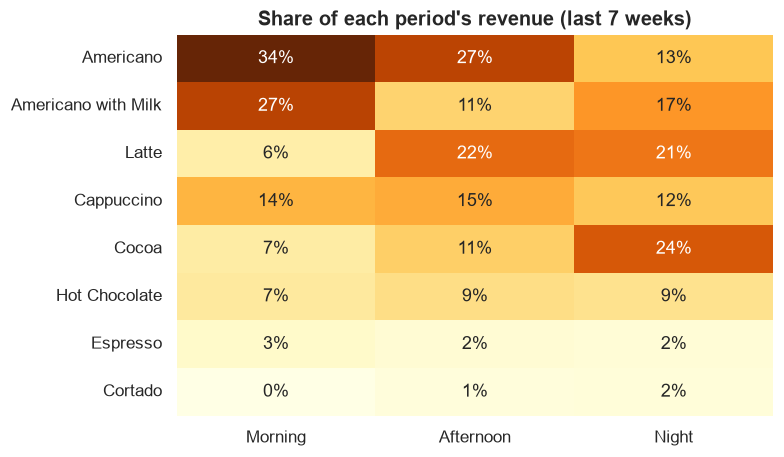

In [9]:
tod = recent.pivot_table(index="coffee_name", columns="Time_of_Day", values="money", aggfunc="sum")[["Morning", "Afternoon", "Night"]]
tod_share = tod.div(tod.sum()).loc[p.index]
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(tod_share, annot=True, fmt=".0%", cmap="YlOrBr", cbar=False, ax=ax)
ax.set(title="Share of each period's revenue (last 7 weeks)", xlabel="", ylabel="")
save_fig("22_product_by_time_of_day_recent.png")

## 6. Recommendations and findings

In [10]:
wd = avg_cups.sum(axis=1)                                   # average cups per day for each weekday
wk_avg, we_avg = wd[["Mon", "Tue", "Wed", "Thu", "Fri"]].mean(), wd[["Sat", "Sun"]].mean()
hr = recent.groupby("hour_of_day").size() / recent["Date"].nunique()
top_hours = hr.nlargest(4)
morning_lead = tod_share["Morning"].idxmax(); night_lead = tod_share["Night"].idxmax()
night_vs_morning = (tod_share["Night"] / tod_share["Morning"]).drop([morning_lead], errors="ignore").nlargest(2)

print(f"1. Total next 30 days: central {central:,.0f}, range {low:,.0f} to {high:,.0f} revenue. Plan with the range, not one number.")
top_move = spread.idxmax()
print(f"1b. The product mix is NOT stable: the monthly share of {top_move} ranges over {spread.max():.0f} percentage points "
      f"(last 7 weeks {p.loc[top_move, 'share']:.0%} vs {mix_share[top_move].mean():.0%} on average). Use the product split for rough planning only.")
print(f"2. Top products by expected cups: " + ", ".join(f"{i} ({body.loc[i, 'cups forecast (central)']:.0f})" for i in body.index[:3]) + ".")
print(f"3. Busiest hours (average cups per day): " + ", ".join(f"{h}:00 ({v:.1f})" for h, v in top_hours.items()) + ". Have milk, cups and a second person ready before these.")
print(f"4. A weekday sells about {wk_avg:.0f} cups, a weekend day about {we_avg:.0f} ({we_avg / wk_avg:.0%} of a weekday). Order and staff for weekdays; keep weekend stock lean.")
print(f"5. Mornings lean towards {morning_lead} ({tod_share.loc[morning_lead, 'Morning']:.0%} of morning revenue); nights lean towards {night_lead} ({tod_share.loc[night_lead, 'Night']:.0%}).")
print("6. Use the 'p80' column of the prep guide as the daily preparation level; use 'median' to judge a normal day.")
print("7. Limits: 13 months of data, one big level jump in Feb 2025, no stock or waste data. Re-check every month.")

1. Total next 30 days: central 14,135, range 13,145 to 14,478 revenue. Plan with the range, not one number.
1b. The product mix is NOT stable: the monthly share of Americano ranges over 21 percentage points (last 7 weeks 25% vs 13% on average). Use the product split for rough planning only.
2. Top products by expected cups: Americano (137), Americano with Milk (82), Latte (66).
3. Busiest hours (average cups per day): 15:00 (1.6), 17:00 (1.6), 16:00 (1.5), 10:00 (1.4). Have milk, cups and a second person ready before these.
4. A weekday sells about 18 cups, a weekend day about 8 (43% of a weekday). Order and staff for weekdays; keep weekend stock lean.
5. Mornings lean towards Americano (34% of morning revenue); nights lean towards Cocoa (24%).
6. Use the 'p80' column of the prep guide as the daily preparation level; use 'median' to judge a normal day.
7. Limits: 13 months of data, one big level jump in Feb 2025, no stock or waste data. Re-check every month.


## What this project shows

- **Cleaning and EDA** (01): data checks, missing days, price and volume, patterns by weekday, hour and product.
- **Baselines** (02): simple methods any model must beat.
- **Holt-Winters and ARIMA** (03): fitted with residual checks, interval coverage and parameter reading.
- **Backtesting** (04): 35 rolling origins, fair comparison, honest conclusion that the advanced models are only slightly better.
- **Business use** (05): product-level range forecast, peak times and a prep guide.

Excel version: `excel/Coffee_Sales_Forecasting.xlsx` (Holt-Winters with Solver, dashboard, backtest).